In [1]:
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
import scipy.io
from CIDER import response_from_all_injections_and_CO2,AOD_from_injection, pattern_from_all_injections_and_CO2
from Toolbox import lat_band_mean, stack_and_zoh_injections, areaweighted_mean, cdo_regrid

In [2]:
run load_all_other_variables.py

In [3]:
## No CO2 forcing: just calculate SAI cooling over time
no_CO2 = np.zeros(len(CO2_forcing_SSP245_month))
total_years = 5
no_injection = np.zeros((total_years*12, 7))

## Update with no CO2 forcing
no_injection_and_CO2 = np.concatenate((no_injection, 
                                       no_CO2[0:total_years*12].reshape(total_years*12, 1)),axis=1)

In [4]:
## Get CESM2 lat/lon grid
test = xr.open_dataset('/home/msaenger/RESTART/ARISE/SSP245/' + \
                       'TREFHT/SSP245_monthly_TREFHT.nc')

cesm_grid = test.isel(time=0, ensemble=0).TREFHT
cesm_grid_lat = cesm_grid.lat#.values
cesm_grid_lon = cesm_grid.lon#.values

## Get CESM2 time values (full record; the deployment window is selected later,
## once the target is known and the SAI start date has been detected)
time_full = xr.open_dataset('/home/msaenger/Perceptions_2025/SSP370_preprocessing_data/' + 
                            'SSP370_full_ensemble_TREFHT_regridded.nc')
time_full

<xarray.Dataset> Size: 4GB
Dimensions:   (ensemble: 50, time: 1032, lat: 96, lon: 192)
Coordinates:
  * time      (time) object 8kB 2015-01-16 00:00:00 ... 2100-12-16 00:00:00
  * lon       (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 352.5 354.4 356.2 358.1
  * lat       (lat) float64 768B -88.57 -86.72 -84.86 ... 84.86 86.72 88.57
  * ensemble  (ensemble) int64 400B 0 1 2 3 4 5 6 7 ... 42 43 44 45 46 47 48 49
Data variables:
    TREFHT    (ensemble, time, lat, lon) float32 4GB ...
    emean     (time, lat, lon) float32 76MB ...
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Fri Jun 13 11:49:35 2025: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [5]:
## Load SSP370 data

path = '/home/msaenger/RESTART/CESM_LENS2/SSP370/TREFHT/combined_by_ensemble_member/regridded/'

ssp = xr.open_mfdataset(path + '*.nc', concat_dim='ensemble',
                                combine='nested', parallel=True)
ssp = ssp.mean('ensemble')
ssp['gmean'] = areaweighted_mean(ssp['TREFHT'])

ssp = ssp.sel(time=slice('2015', '2045'))

ssp = ssp.chunk({'time': 372}) 
ssp

<xarray.Dataset> Size: 27MB
Dimensions:  (time: 372, lat: 96, lon: 192)
Coordinates:
  * time     (time) object 3kB 2015-01-16 00:00:00 ... 2045-12-16 00:00:00
  * lon      (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 352.5 354.4 356.2 358.1
  * lat      (lat) float64 768B -88.57 -86.72 -84.86 -83.0 ... 84.86 86.72 88.57
Data variables:
    TREFHT   (time, lat, lon) float32 27MB dask.array<chunksize=(372, 96, 192), meta=np.ndarray>
    gmean    (time) float64 3kB dask.array<chunksize=(372,), meta=np.ndarray>

In [6]:
g = ssp.gmean
print(len(g.__dask_graph__()))   # number of tasks
print(g.data.npartitions)        # 1032

237784
1


In [7]:
from dask.diagnostics import ProgressBar
with ProgressBar():
    gm = ssp.gmean.compute()

[########################################] | 100% Completed | 63.25 s


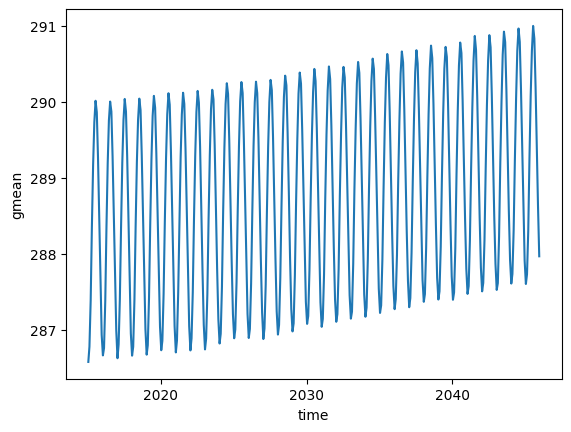

In [8]:
gm.plot()

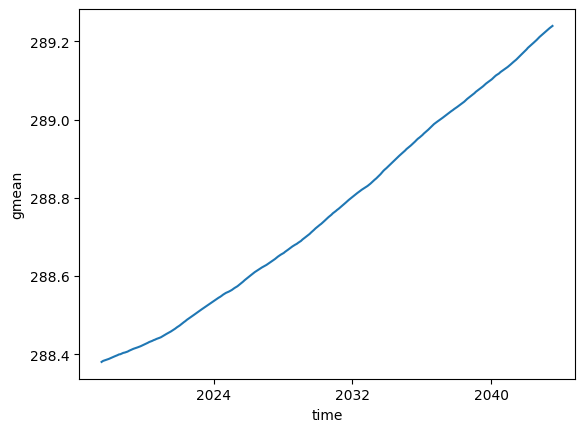

In [9]:
gm_smoothed = gm.rolling(time=60, center=True).mean()
gm_smoothed.plot()

In [10]:
## Load CESM2 PiControl data to check what the preindustrial global mean temperature was 
ds = xr.open_mfdataset('/home/msaenger/InVERT/CESM2_piControl/TREFHT/Isolated/*.nc', 
                        concat_dim='time', combine='nested', parallel=True)

T = ds['TREFHT']                      # ds = piControl dataset; units = K
T = T.chunk({'time': 1200})          

## Area-weighted global mean at each time step (regular lat/lon grid, so cos(lat) is enough)
weights = np.cos(np.deg2rad(ds['lat']))
gmst = T.weighted(weights).mean(['lat', 'lon']).compute()    # (time,)

## Preindustrial GMST = long-term mean, weighting each month by its length
days = gmst['time'].dt.days_in_month
pi_gmst = gmst.weighted(days).mean('time')
print(f'Preindustrial GMST (all 2000 yr): {pi_gmst.item():.3f} K')

spinup_yrs = 150
gmst_post = gmst.isel(time=slice(12 * spinup_yrs, None))
pi_gmst = gmst_post.weighted(gmst_post['time'].dt.days_in_month).mean('time')
print(f'Preindustrial GMST (drop 150 spinup years): {pi_gmst.item():.3f} K')

## Apply Annual mean weighted by month

month_len = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])   # noleap
vals = gmst.values.reshape(2000, 12)                                      # (year, month)
annual = xr.DataArray((vals * month_len).sum(axis=1) / month_len.sum(),
                      dims='year', coords={'year': np.arange(1, 2001)})

pi_gmst = annual.isel(year=slice(spinup_yrs, None)).mean()
print(f'Preindustrial GMST (annual mean with 150 spin-up years dropped): {pi_gmst.item():.3f} K')

target = float(pi_gmst + 1.5)   # plain float: a 0-d DataArray breaks numpy-array arithmetic in the optimizer
print(target)

Preindustrial GMST (all 2000 yr): 287.198 K
Preindustrial GMST (drop 150 spinup years): 287.219 K
Preindustrial GMST (annual mean with 150 spin-up years dropped): 287.218 K
288.7180180047019


In [11]:
## Detect when the background (smoothed SSP370) GMST first exceeds the target; SAI starts one month later
gm_valid = gm_smoothed.dropna('time')              # centered rolling mean is NaN at both ends
above = (gm_valid > target).values

if not above.any():
    raise ValueError('Smoothed SSP370 GMST never exceeds the target in the loaded record')
if above[0]:
    raise ValueError('Smoothed GMST is already above the target at the start of the valid record; no crossing to detect')

t_cross = gm_valid.time.values[int(np.argmax(above))]            # first month above target
i_cross = gm_smoothed.get_index('time').get_loc(t_cross)         # position on the full gm_smoothed axis

i_start = i_cross + 1                                            # SAI starts exactly one month later
i_end   = i_start + total_years*12 - 1
assert i_end < gm_smoothed.sizes['time'], 'Deployment window runs past the end of the loaded SSP370 record'

sai_start = gm_smoothed.time.values[i_start]
sai_end   = gm_smoothed.time.values[i_end]
timeslice = slice(f'{sai_start.year:04d}-{sai_start.month:02d}', f'{sai_end.year:04d}-{sai_end.month:02d}')

time = time_full.sel(time=timeslice)                             # used for the output file's time axis
assert time.sizes['time'] == total_years*12
assert not np.isnan(gm_smoothed.isel(time=slice(i_start, i_end+1))).any()

print(f'Target:                      {target:.4f} K')
print(f'First month above target:    {t_cross.year}-{t_cross.month:02d}  '
      f'({float(gm_smoothed.isel(time=i_cross)):.4f} K; previous month {float(gm_smoothed.isel(time=i_cross-1)):.4f} K)')
print(f'SAI start (one month later): {sai_start.year}-{sai_start.month:02d}')
print(f'Deployment window:           {timeslice.start} to {timeslice.stop}  ({total_years} yr)')

Target:                      288.7180 K
First month above target:    2029-10  (288.7181 K; previous month 288.7146 K)
SAI start (one month later): 2029-11
Deployment window:           2029-11 to 2034-10  (5 yr)


## Optimal 30N/30S injection schedule to hold GMST at the 1.5 °C target

Annual injection rate at each of 30N and 30S is treated as a free parameter and fitted so that `SSP370 smoothed GMST + CIDER SAI response` stays at `target`.

**Setup**
- `target` = CESM2 piControl preindustrial GMST + 1.5 K (cell above).
- SAI start is detected automatically: one month after the smoothed SSP370 GMST first exceeds `target`. The window then runs for `total_years` from that month.
- Sanity-check compares the emulator global-mean response with the pattern-based global mean. 

In [12]:
import os
from scipy.optimize import least_squares

years_represented_by_array_element = 1

# SSP370 smoothed GMST over the window, one value per month (K)
baseline = gm_smoothed.sel(time=timeslice).values
baseline

array([288.72162164, 288.72455245, 288.72774438, 288.73059451,
       288.73336886, 288.73650428, 288.74008117, 288.74355003,
       288.74705912, 288.75054912, 288.75344945, 288.75656116,
       288.76029706, 288.76308308, 288.76599061, 288.7690003 ,
       288.77172423, 288.77484451, 288.77769517, 288.7814234 ,
       288.78458288, 288.78779885, 288.7912322 , 288.79448976,
       288.79743767, 288.80035638, 288.80318213, 288.80623645,
       288.80942822, 288.81218426, 288.81485185, 288.81766464,
       288.82054729, 288.82294687, 288.82526413, 288.82757775,
       288.83014033, 288.83301608, 288.83618919, 288.83945587,
       288.84293854, 288.84624754, 288.8492772 , 288.85282963,
       288.8564668 , 288.86033487, 288.86466094, 288.86895637,
       288.87242999, 288.87558157, 288.87925545, 288.88254331,
       288.88619629, 288.88969548, 288.89322213, 288.89681749,
       288.9008391 , 288.90402933, 288.9075394 , 288.91108781])

In [13]:
assert baseline.shape[0] == total_years*12 and not np.isnan(baseline).any()

def build_inputs(x):
    """x = annual injection at EACH of 30N and 30S (length total_years). Returns emulator input array."""
    z = np.zeros(total_years)
    inj = stack_and_zoh_injections((z, x, z, z, z, x, z),   # 60N, 30N, 15N, 0, 15S, 30S, 60S
                                   years_represented_by_array_element*12)
    return np.concatenate((inj, no_CO2[0:total_years*12].reshape(-1, 1)), axis=1)

def sai_response(x):
    """Global-mean SAI temperature response (K, monthly) from the emulator."""
    r = response_from_all_injections_and_CO2(build_inputs(x), param_AOD_all, param_T_all)
    return np.asarray(r).squeeze()

def gmst_with_sai(x):
    return baseline + sai_response(x)

In [14]:
## Sanity check: emulator global-mean response vs. global mean of the pattern output
x_chk = np.array([1, .9, .8, .7, .6])
r_chk = sai_response(x_chk)
print('response shape:', r_chk.shape, '(expected', (total_years*12,), ')')

p_chk = pattern_from_all_injections_and_CO2(build_inputs(x_chk), param_AOD_all, param_T_all, all_T_patterns_scaled)  # (lon, lat, time)
w = np.cos(np.deg2rad(np.asarray(cesm_grid_lat)))
gm_p = np.einsum('xyt,y->t', p_chk, w) / (w.sum() * p_chk.shape[0])
print('max |emulator GM response - pattern GM| (K):', np.abs(r_chk - gm_p).max())
print('max |SAI response| (K):', np.abs(r_chk).max())

response shape: (60,) (expected (60,) )
max |emulator GM response - pattern GM| (K): 6.744520095192108e-09
max |SAI response| (K): 0.1119566704314979


In [15]:
## Optimize the annual injection schedule
fit_from = 0        # first month included in the fit (e.g. 12 to ignore year 1 if aerosol spin-up can't be beaten)
max_rate = 20.0     # cap per latitude band
lam = 0.05          # smoothness penalty on 2nd differences of the schedule (0 = none)

def residuals(x):
    fit = (gmst_with_sai(x) - target)[fit_from:]
    smooth = lam * np.diff(x, n=2) if len(x) > 2 else np.array([])
    return np.concatenate([fit, smooth])

sol = least_squares(residuals, x0=np.full(total_years, 1.0), bounds=(0, max_rate))
x_opt = sol.x

T_opt = gmst_with_sai(x_opt)
print('success:', sol.success, '|', sol.message)
print('per-band injection by year (30N = 30S):', np.round(x_opt, 3))
print('total injection by year (30N + 30S):   ', np.round(2*x_opt, 3))
print('rms miss vs target (K): %.4f' % np.sqrt(np.mean((T_opt - target)[fit_from:]**2)))
print('max |miss| (K):         %.4f' % np.abs((T_opt - target)[fit_from:]).max())
if np.any(np.isclose(x_opt, max_rate)) or np.any(np.isclose(x_opt, 0)):
    print('WARNING: schedule is at a bound (0 or max_rate); target may not be reachable in this window.')

success: True | `ftol` termination condition is satisfied.
per-band injection by year (30N = 30S): [0.755 0.868 1.054 1.344 1.652]
total injection by year (30N + 30S):    [1.51  1.736 2.107 2.688 3.304]
rms miss vs target (K): 0.0012
max |miss| (K):         0.0028


In [16]:
## Generate gridded output for the optimal schedule (single CDO regrid, outside any loop)
basepath = '/home/msaenger/CIDER/CMIP7_stabilization/'
targetgrid = '/home/msaenger/RESTART/targetgrid.nc'
os.makedirs(basepath, exist_ok=True)

p = pattern_from_all_injections_and_CO2(build_inputs(x_opt), param_AOD_all, param_T_all, all_T_patterns_scaled)

ds = xr.Dataset(data_vars={"T": (["lon", "lat", "time"], p)},
                coords={"lon": cesm_grid_lon, "lat": cesm_grid_lat, "time": time.time},
                attrs={"description": "CIDER T change from SSP370 baseline for optimized 30N/30S injection schedule (lon, lat, time)",
                       "target_K": float(target)})
ds = ds.transpose('time', 'lat', 'lon')

opt_file = basepath + 'optimal_Tgyr.nc'
ds.to_netcdf(opt_file)
cdo_regrid(targetgrid, opt_file, opt_file + '_regridded.nc')

pd.DataFrame({'year_index': np.arange(total_years),
              'per_band_injection': x_opt,
              'total_injection': 2*x_opt}).to_csv(basepath + 'optimal_injection_schedule.csv', index=False)

cdo    remapbil: Bilinear weights from lonlat (288x192) to gaussian (192x96) grid
cdo    remapbil: Processed 3317760 values from 1 variable over 60 timesteps [0.05s 2433MB].


Warning (cdfScanVarAttr): NetCDF: Variable not found - time_bnds
Warning (cdfScanVarAttr): NetCDF: Variable not found - lat_bnds
Warning (cdfScanVarAttr): NetCDF: Variable not found - lon_bnds
Warning (cdfInqContents): Coordinates variable time can't be assigned!
Warning (cdfInqContents): Coordinates variable ensemble can't be assigned!


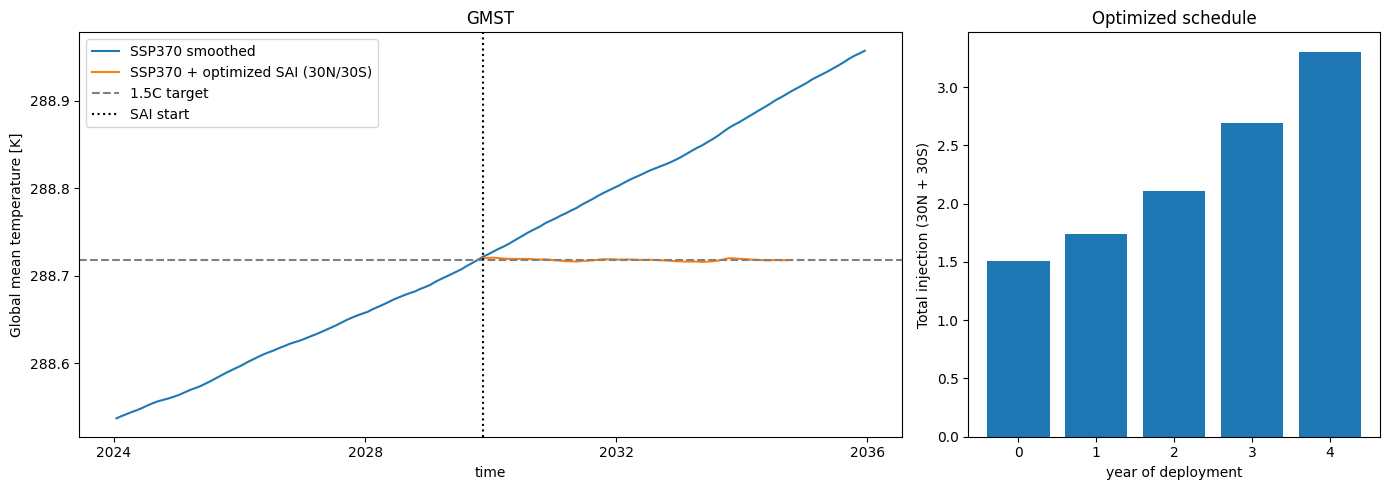

In [17]:
## Plot: optimized run vs. baseline and target
opt = xr.open_dataset(opt_file + '_regridded.nc')
opt['gmean'] = areaweighted_mean(opt['T'])
ssp_cider_opt = opt.gmean.sel(time=timeslice) + gm_smoothed.sel(time=timeslice)

ssp_extended = gm_smoothed.sel(time=slice(str(sai_start.year - 5), str(sai_end.year + 1)))

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [2, 1]})

ssp_extended.plot(ax=ax[0], label='SSP370 smoothed')
ssp_cider_opt.plot(ax=ax[0], label='SSP370 + optimized SAI (30N/30S)')
ax[0].axhline(target, color='gray', linestyle='--', label='1.5C target')
ax[0].axvline(sai_start, color='k', linestyle=':', label='SAI start')
ax[0].set_ylabel('Global mean temperature [K]'); ax[0].set_xlabel('time'); ax[0].legend(); ax[0].set_title('GMST')

yrs = np.arange(total_years)
ax[1].bar(yrs, 2*x_opt)
ax[1].set_xlabel('year of deployment'); ax[1].set_ylabel('Total injection (30N + 30S)')
ax[1].set_title('Optimized schedule')
plt.tight_layout()

In [19]:
test = xr.open_dataset(basepath + 'optimal_Tgyr.nc_regridded.nc')
test

<xarray.Dataset> Size: 9MB
Dimensions:  (time: 60, lon: 192, lat: 96)
Coordinates:
  * time     (time) object 480B 2029-11-15 00:00:00 ... 2034-10-16 00:00:00
  * lon      (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 352.5 354.4 356.2 358.1
  * lat      (lat) float64 768B -88.57 -86.72 -84.86 -83.0 ... 84.86 86.72 88.57
Data variables:
    T        (time, lat, lon) float64 9MB ...
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    description:  CIDER T change from SSP370 baseline for optimized 30N/30S i...
    target_K:     288.7180180047019
    history:      Mon Oct 19 14:09:43 2026: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [21]:
## Load CESM2 LENS2 Historical TREFHT data

In [22]:
target

288.7180180047019